In [277]:
!unzip -o data.zip -d data

Archive:  data.zip
  inflating: data/dataset.txt        


In [295]:
with open("data/dataset.txt", "r") as file:
    data = file.read().split("\n")

In [296]:
import pandas as pd
import numpy as np


labels = list(map(lambda x: list(map(lambda y: y[len('__label__'):], x.split(" ")[0].split(","))), data))
comments = list(map(lambda x: " ".join(x.split(" ")[1:]), data))

In [297]:
df = pd.DataFrame(np.array([labels, comments], dtype="object").T, columns = ["labels", "comment"])
df.head(5)

,labels,comment
0,[INSULT],скотина! что сказать
1,[NORMAL],я сегодня проезжала по рабочей и между домами ...
2,[NORMAL],очередной лохотрон. зачем придумывать очередно...
3,[NORMAL],"ретро дежавю ... сложно понять чужое сердце , ..."
4,[NORMAL],а когда мы статус агрогородка получили?


In [298]:
l = list(map(lambda x: '_'.join(x), df['labels'].value_counts().index.to_list()))
l.remove('')
labels_n = {}
for labels in l:
    labels_n[labels] = 2000
labels_n['NORMAL'] = 4000
dfs = []
for labels in l:
    dfs.append(df[df['labels'].apply(lambda x: '_'.join(x)) == labels].head(labels_n[labels]))
df = pd.concat(dfs)
df.shape

(14016, 2)

In [299]:
df.describe()

,labels,comment
count,14016,14016
unique,8,14016
top,[NORMAL],я сегодня проезжала по рабочей и между домами ...
freq,4000,1


In [300]:
df.isnull().sum()

,0
labels,0
comment,0


In [301]:
df.astype(str).duplicated().sum()

0

In [302]:
df[(df['labels'].apply(len) == 0)]

,labels,comment


In [303]:
empty_objects = df[(df['labels'].apply(lambda x: '' in x)) | (df['comment'] == '')].index
empty_objects

Index([], dtype='int64')

In [304]:
df = df.drop(empty_objects)

Дальше мы можем посмотреть на данные как хотел автор ( с классификацией ), а можем сделать target бинарным, где NORMAL будет считаться, как не токсичный комментарий. Давайте для начала посмотрим на данные с несколькими классами

Давайте убедимся, что нету rows, где есть несколько labels и NORMAL

In [305]:
df[(df['labels'].apply(len) > 1) & (df['labels'].apply(lambda x: 'NORMAL' in x))]

,labels,comment


Почистим теперь данные от различных ссылок, знаков препинания, стопслов и прочего.

Вопрос что делать с эмодзи. Мы можем переводить их в английские слова. Однако, не можем в русские. Поскольку мы анализируем русские комментарии, то, возможно, имеет смысл отбросить тогда эмодзи. С другой стороны нужно тестировать и, возможно, если удалить все англоязычные слова и оставить только англоязычное представление эмодзи, то у нас получится хороший результат. Напишем две функции, где одна удаляет эмодзи, а другая превращает в англоязычные слова. Для примера пока возьмем перевод в англоязычные слова.

In [306]:
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [307]:
%pip install emoji

import re
import emoji
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize


nltk.download('stopwords')
nltk.download('punkt')

def clean_text(text):
  res = text.lower()

  # удалим все, что не относится к русским словам
  res = re.sub('[^а-яА-ЯёЁ\s]', '', res)

  # удалим лишние пробельные символы
  res = re.sub('\s+', ' ', res)

  # Заменяем эмодзи на английские слова
  res = emojis_words(res)

  # Стоп-слова: удаление стоп-слов - это стандартная практика очистки текстов
  res = remove_stopwords(res, [])

  return res

def remove_stopwords(text, l):
  stop_words = set(stopwords.words("russian") + l)
  tokens = word_tokenize(text)
  tokens = [token for token in tokens if token not in stop_words]
  res = ' '.join(tokens)

  return res

def emojis_words(text):
  res = emoji.demojize(text, delimiters=(" ", " "))
  res = res.replace(":", "").replace("_", " ")
  return res

def remove_emojis(text):
  return emoji.replace_emoji(text, replace="")

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!


In [308]:
df['comment'] = df['comment'].apply(clean_text)
df.head(5)

,labels,comment
1,[NORMAL],сегодня проезжала рабочей домами снитенко гомо...
2,[NORMAL],очередной лохотрон придумывать очередной налог...
3,[NORMAL],ретро дежавю сложно понять чужое сердце лиш ощ...
4,[NORMAL],статус агрогородка получили
5,[NORMAL],августа поздно вечером нашли такую потеряшку р...


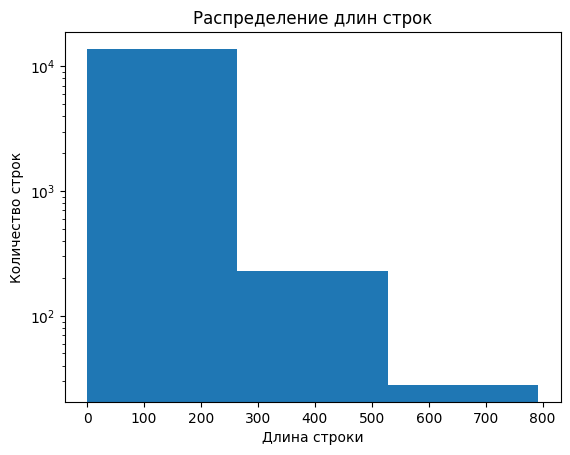

In [309]:
import matplotlib.pyplot as plt


plt.hist(df['comment'].str.len(), bins=3)
plt.xlabel('Длина строки')
plt.ylabel('Количество строк')
plt.title('Распределение длин строк')
plt.yscale('log')
plt.show()

Видно, что здесь есть довольно мало длинных комментариев. Возможно, их имеет смысл удалить, но я бы попробовал с ними и без. Тем более 800 символов с пробелами это не очень много ( для комментария может и много, но для постов допустим не сильно )

Теперь мы можем смело разделять df по классам с explode(), чтобы было удобнее работать с колонкой labels. Сделаю тут же еще df_bin, где будем смотреть не на labels, а на отдельную колонку toxic

In [310]:
df_class = df.explode('labels')

In [311]:
df_class['labels'].unique()

array(['NORMAL', 'INSULT', 'THREAT', 'OBSCENITY'], dtype=object)

In [312]:
df_class.describe()

,labels,comment
count,18208,18208
unique,4,13714
top,INSULT,
freq,5942,21


In [313]:
df_bin = df.copy()

In [314]:
df_bin['toxic'] = df_bin['labels'].apply(lambda x: 'NORMAL' not in x)
df_bin.describe()

,labels,comment,toxic
count,14016,14016,14016
unique,8,13714,2
top,[NORMAL],,True
freq,4000,21,10016


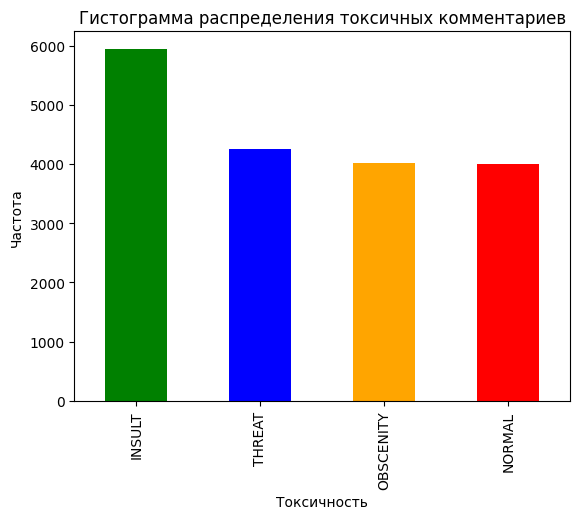

In [315]:
df_class['labels'].value_counts().plot(kind='bar', color=['green', 'blue', 'orange', 'red'])
plt.xlabel('Токсичность')
plt.ylabel('Частота')
plt.title('Гистограмма распределения токсичных комментариев')
plt.show()

Для наглядности посмотрим что происходит в бинарном случае

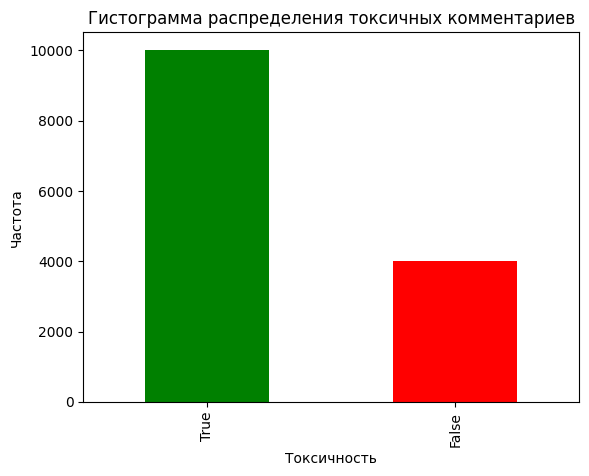

In [316]:
df_bin['toxic'].value_counts().plot(kind='bar', color=['green', 'red'])
plt.xlabel('Токсичность')
plt.ylabel('Частота')
plt.title('Гистограмма распределения токсичных комментариев')
plt.show()

Теперь посмотрим на частотный анализ слов. Также на частотный анализ слов с лемматизацией и стеммингом

[('это', 1280), ('тебе', 541), ('хуй', 477), ('таких', 430), ('расстрелять', 330), ('ещё', 320), ('рот', 304), ('просто', 285), ('этих', 285), ('нужно', 285)]


<Axes: title={'center': 'Частотный анализ слов'}, xlabel='Samples', ylabel='Counts'>

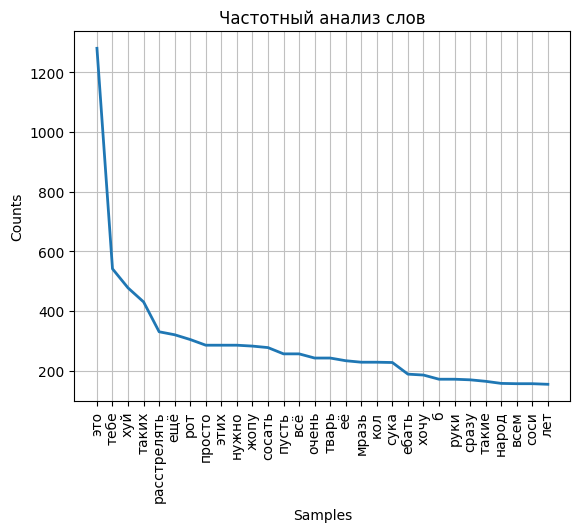

In [317]:
from nltk.probability import FreqDist


comments = " ".join(df['comment'].tolist())
comments_tokens = word_tokenize(comments)
text = nltk.Text(comments_tokens)
f_dist = FreqDist(text)
print(f_dist.most_common(10))
f_dist.plot(30, cumulative=False, title='Частотный анализ слов')

Видно, что здесь остались еще шумные слова, которые нам не помогут. Например, 'это' и 'очень'. Давайте тоже их исключим.

In [318]:
stop_words = ['это', 'очень']
df['comment'] = df['comment'].apply(remove_stopwords, args=(stop_words,))

df = df[df['comment'].apply(len) != 0]

[('тебе', 541), ('хуй', 477), ('таких', 430), ('расстрелять', 330), ('ещё', 320), ('рот', 304), ('просто', 285), ('этих', 285), ('нужно', 285), ('жопу', 282)]


<Axes: title={'center': 'Частотный анализ слов'}, xlabel='Samples', ylabel='Counts'>

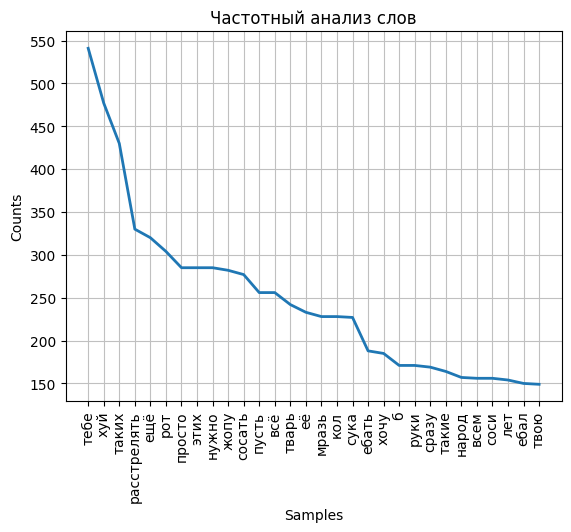

In [319]:
from nltk.probability import FreqDist


comments = " ".join(df['comment'].tolist())
comments_tokens = word_tokenize(comments)
text = nltk.Text(comments_tokens)
f_dist = FreqDist(text)
print(f_dist.most_common(10))
f_dist.plot(30, cumulative=False, title='Частотный анализ слов')

Есть еще всякие 'б', 'оо'. Давайте сначала глянем на стемминг и лемматизацию

('так', 1106)
('ху', 626)
('сво', 616)
('тво', 549)
('теб', 543)
('эт', 541)
('твар', 511)
('еба', 459)
('сам', 450)
('сук', 426)


<Axes: title={'center': 'Частотный анализ слов со стеммингом'}, xlabel='Samples', ylabel='Counts'>

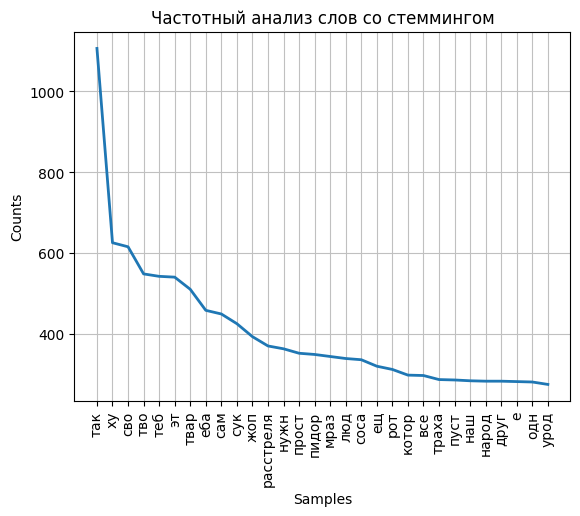

In [330]:
# Стемминг
from nltk.stem.snowball import SnowballStemmer


snow_stemmer = SnowballStemmer(language='russian')
text_stemmed = map(lambda word: snow_stemmer.stem(word), text)
f_dist = FreqDist(text_stemmed)
print('\n'.join(map(str, f_dist.most_common(10))))
f_dist.plot(30, cumulative=False, title='Частотный анализ слов со стеммингом')

Применили стемминг и видно, что всяких 'б' и 'оо' уже нет. Давайте еще глянем на лемматизацию

In [331]:
!pip install pymorphy2
import pymorphy2

('такой', 1090)
('сосать', 716)
('свой', 615)
('хуй', 609)
('ты', 584)
('твой', 550)
('человек', 512)
('тварь', 502)
('этот', 460)
('хотеть', 451)


<Axes: title={'center': 'Частотный анализ слов с лемматизацией'}, xlabel='Samples', ylabel='Counts'>

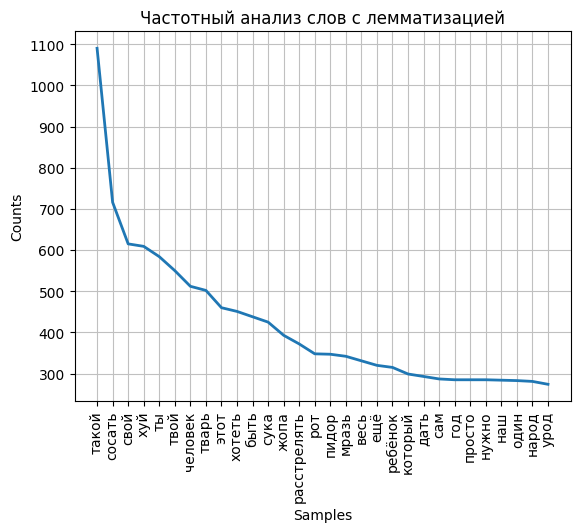

In [332]:
# Лемматизация
morph = pymorphy2.MorphAnalyzer()

text_lemmatized = map(lambda word: morph.parse(word)[0].normal_form, text)
f_dist = FreqDist(text_lemmatized)
print('\n'.join(map(str, f_dist.most_common(10))))
f_dist.plot(30, cumulative=False, title='Частотный анализ слов с лемматизацией')

Есть небольшая разница. Список у лемматизации на самом деле более интересный, что логично. В принципе, 6 минут на 248к комментов не очень долго для нас. Тем более, что мы целимся на комменты в соцсети, что необязательно иметь мгновенный отклик. Вот если целить на стримы, то там желательно быстро реагировать. Там можно было бы взять стемминг.

In [333]:
df['tokenized'] = df['comment'].str.split()

In [334]:
df['comment_lemmatized'] = df['tokenized'].apply(lambda words: [morph.parse(word)[0].normal_form for word in words])

In [335]:
df['comment_lemmatized'].head(5)

,comment_lemmatized
1,"[сегодня, проезжать, рабочий, дом, снитенко, г..."
2,"[очередной, лохотрон, придумывать, очередной, ..."
3,"[ретро, дежавю, сложно, понять, чужое, сердце,..."
4,"[статус, агрогородок, получить]"
5,"[август, поздно, вечером, наслать, такой, поте..."


('хуй сосать', 91)
('сосать хуй', 57)
('дать бог', 44)
('гореть ад', 44)
('твой мама', 42)
('суд следствие', 38)
('друг друг', 36)
('этот тварь', 34)
('твой рот', 34)
('рот ебал', 33)


<Axes: title={'center': '2-grams'}, xlabel='Samples', ylabel='Counts'>

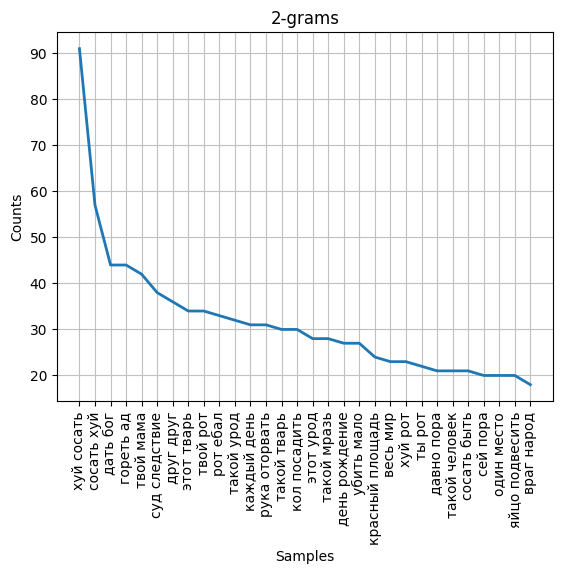

In [336]:
from nltk.util import ngrams
from functools import reduce

df['2-grams'] = df['comment_lemmatized'].apply(lambda row: [' '.join(grams) for grams in ngrams(row, 2)])
bigrams = [item for sublist in df['2-grams'] for item in sublist]
f_dist = FreqDist(bigrams)
print('\n'.join(map(str, f_dist.most_common(10))))
f_dist.plot(30, cumulative=False, title='2-grams')

('твой рот ебал', 15)
('гореть ты ад', 14)
('дать бог здоровье', 12)
('помощь поддержка дружеский', 9)
('поддержка дружеский хватать', 9)
('дружеский хватать хозяйство', 9)
('хватать хозяйство вещь', 9)
('хозяйство вещь малый', 9)
('вещь малый дело', 9)
('малый дело важный', 9)


<Axes: title={'center': '3-grams'}, xlabel='Samples', ylabel='Counts'>

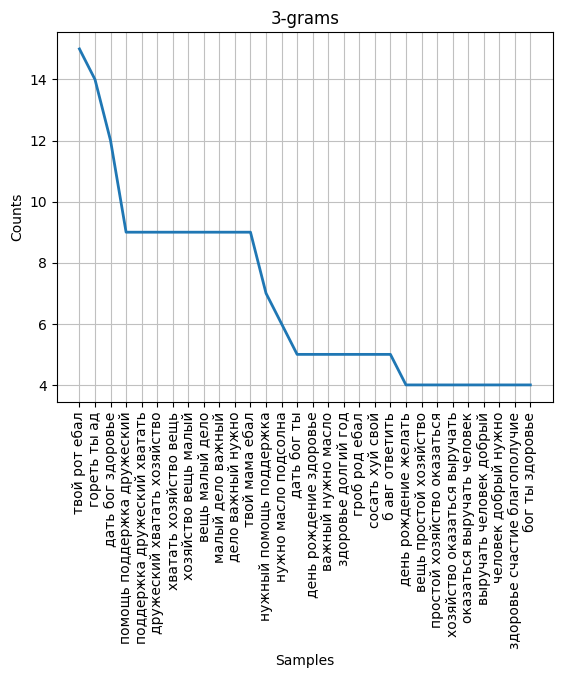

In [337]:
df['3-grams'] = df['comment_lemmatized'].apply(lambda row: [' '.join(grams) for grams in ngrams(row, 3)])
threegrams = [item for sublist in df['3-grams'] for item in sublist]
f_dist = FreqDist(threegrams)
print('\n'.join(map(str, f_dist.most_common(10))))
f_dist.plot(30, cumulative=False, title='3-grams')

In [338]:
text_lemmatized = ' '.join([word for comment in df['comment_lemmatized'] for word in comment])

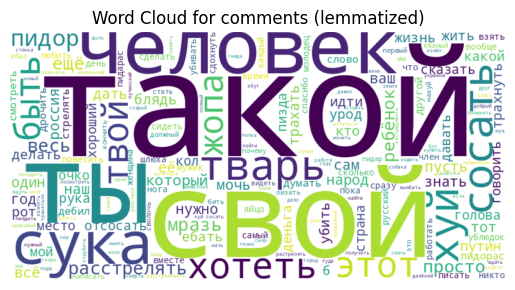

In [339]:
from wordcloud import WordCloud


wordcloud_toxic = WordCloud(width=800, height=400, background_color='white').generate(text_lemmatized)
plt.imshow(wordcloud_toxic, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud for comments (lemmatized)')
plt.show()

In [340]:
text_lemmatized = ' '.join([word for comment in df[df_bin['toxic']]['comment_lemmatized'] for word in comment])

<ipython-input-340-2604adcbe358>:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  text_lemmatized = ' '.join([word for comment in df[df_bin['toxic']]['comment_lemmatized'] for word in comment])


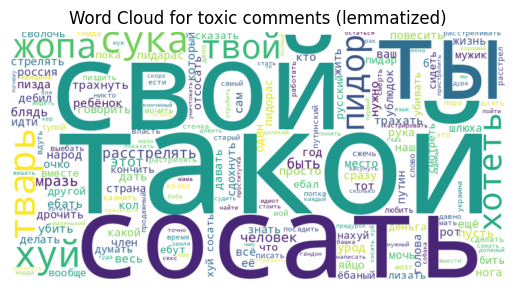

In [341]:
wordcloud_toxic = WordCloud(width=800, height=400, background_color='white').generate(text_lemmatized)
plt.imshow(wordcloud_toxic, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud for toxic comments (lemmatized)')
plt.show()

Датасет довольно большой, что довольно хорошо при обучении. Хорошо, что есть классификация, что дает возможность использовать его под разные задачи. Можно еще поэкспериментировать при построении модельки со стопсловами. Например, меня
тут смущают слова 'такой' и 'свой'. Их можно попробовать добавить в стопслова после леммитизации. Word Cloud для токсичных комментариев выглядит довольно хорошо. Действительно, есть много токсичных слов. В датасете так же есть эмодзи, которые, возможно, будут тоже полезны при построении модели.

Уберем смущающие нас слова 'свой' и 'такой'

In [342]:
stopwords_extra = ['свой', 'такой']
text_lemmatized = ' '.join([word for comment in df['comment_lemmatized'] for word in comment if word not in stopwords_extra])

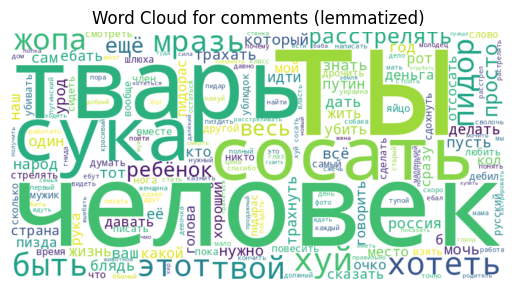

In [343]:
wordcloud_toxic = WordCloud(width=800, height=400, background_color='white').generate(text_lemmatized)
plt.imshow(wordcloud_toxic, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud for comments (lemmatized)')
plt.show()

In [344]:
text_lemmatized = ' '.join([word for comment in df[df_bin['toxic']]['comment_lemmatized'] for word in comment if word not in stopwords_extra])

<ipython-input-344-b9089b6177d4>:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  text_lemmatized = ' '.join([word for comment in df[df_bin['toxic']]['comment_lemmatized'] for word in comment if word not in stopwords_extra])


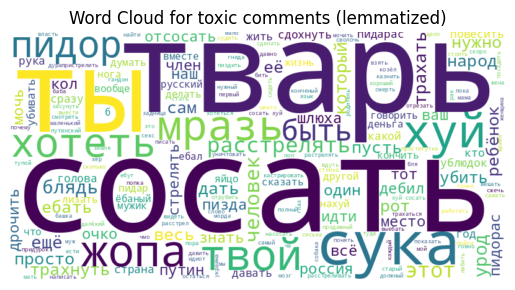

In [346]:
wordcloud_toxic = WordCloud(width=800, height=400, background_color='white').generate(text_lemmatized)
plt.imshow(wordcloud_toxic, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud for toxic comments (lemmatized)')
plt.show()

Не сказать что стало приятнее, но по крайней мере нагляднее :)

Посмотрим на эти графики в рамках каждого класса

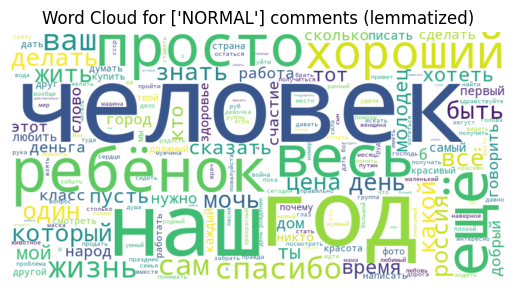

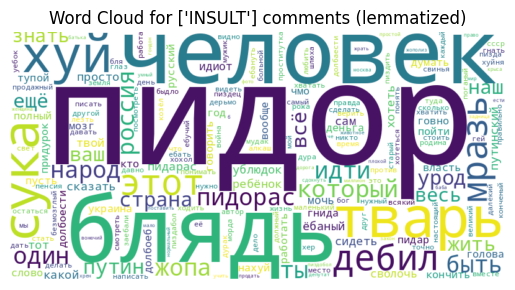

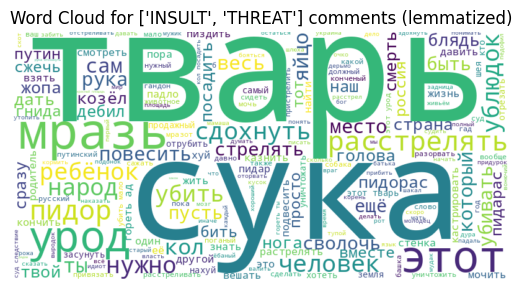

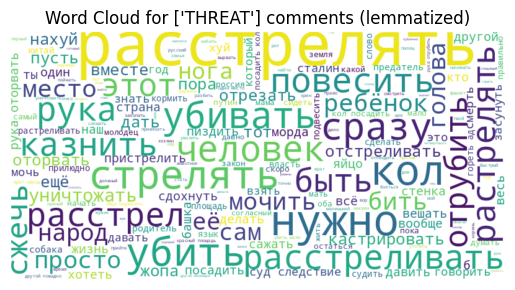

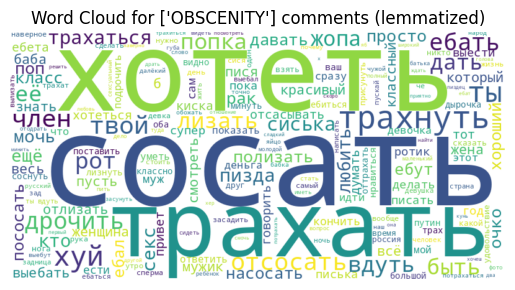

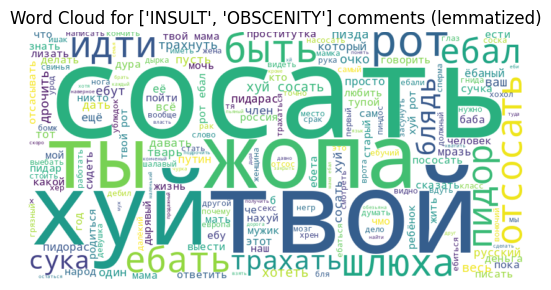

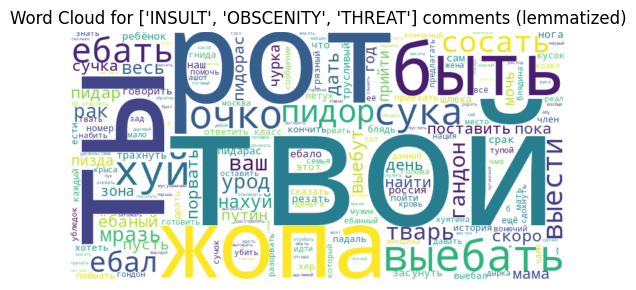

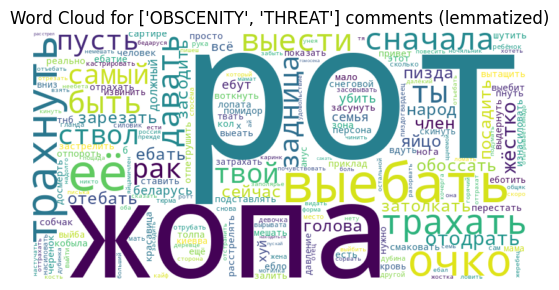

In [347]:
labels_list = df['labels'].value_counts().index.tolist()
df['labels_str'] = df['labels'].map(lambda x: '_'.join(x))

for labels in labels_list:
    text_lemmatized = ' '.join([word for comment in df[df['labels_str'] == '_'.join(labels)]['comment_lemmatized'] for word in comment if word not in stopwords_extra])
    wordcloud_toxic = WordCloud(width=800, height=400, background_color='white').generate(text_lemmatized)
    plt.imshow(wordcloud_toxic, interpolation='bilinear')
    plt.axis('off')
    plt.title(f'Word Cloud for {labels} comments (lemmatized)')
    plt.show()

Явно наблюдается различие между классами 'THREAT', 'OBSCENITY' и 'INSULT', классы с несколькими метками содержат популярные слова из соответствующих word cloud-ов.

Посмотрим на лемматизацию по классам

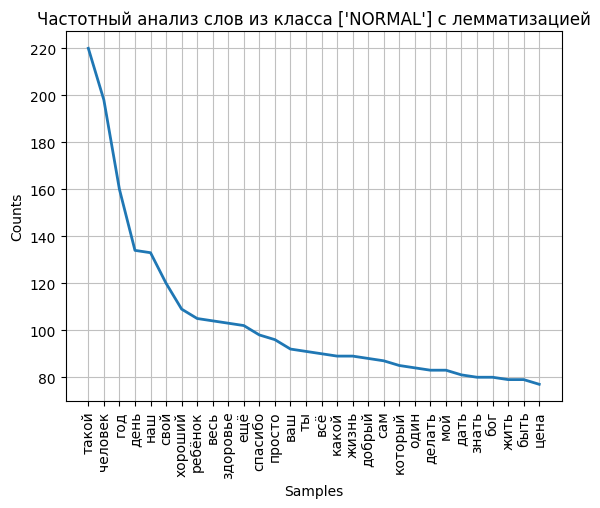

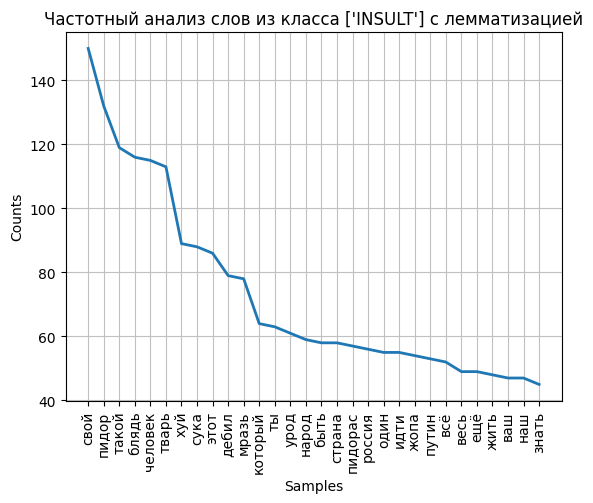

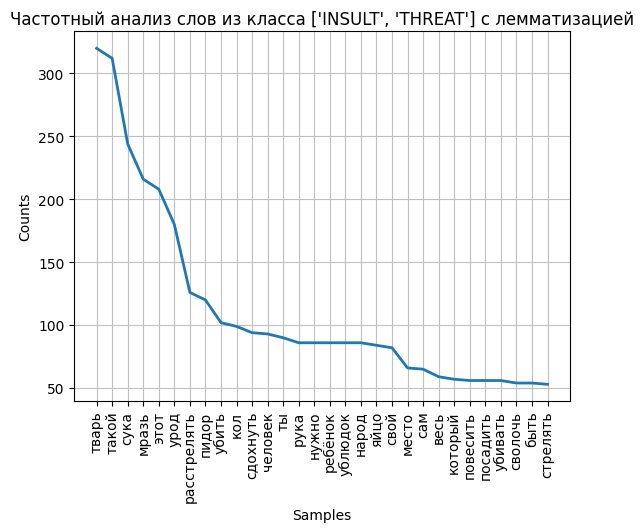

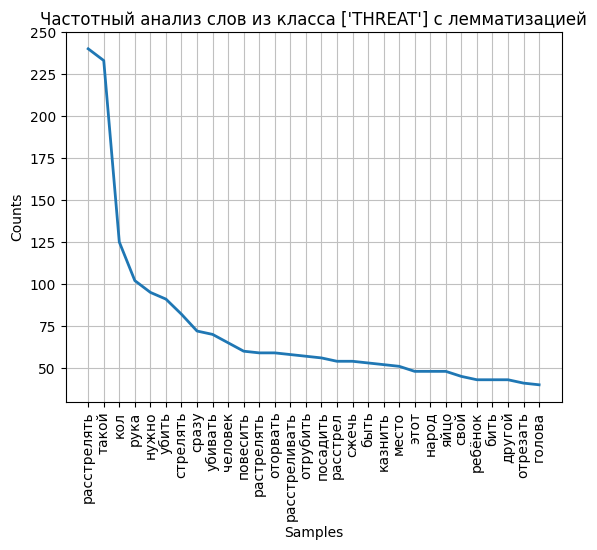

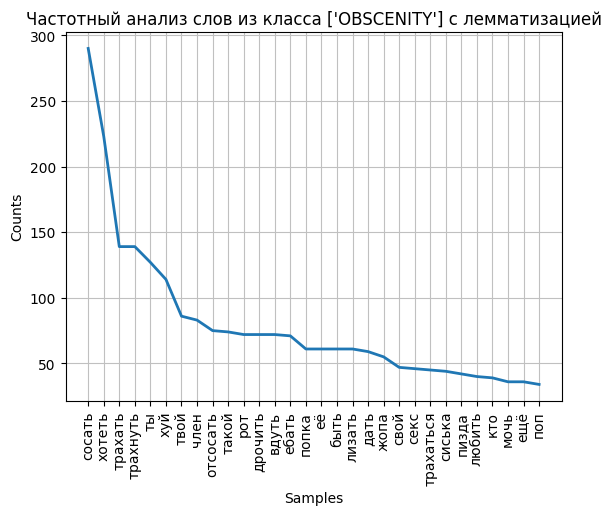

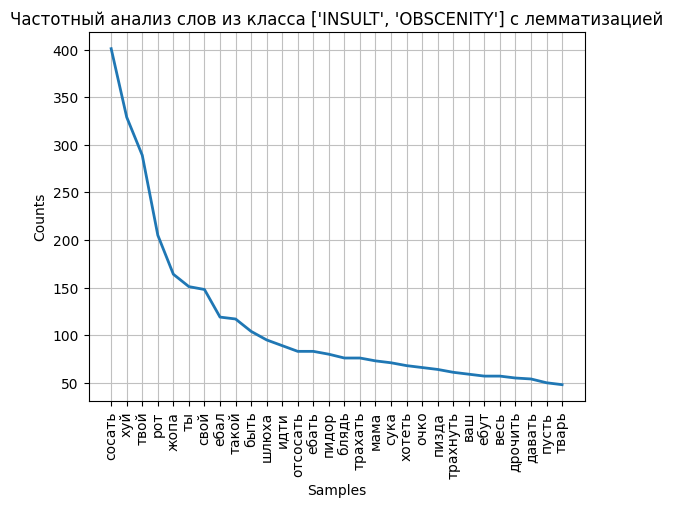

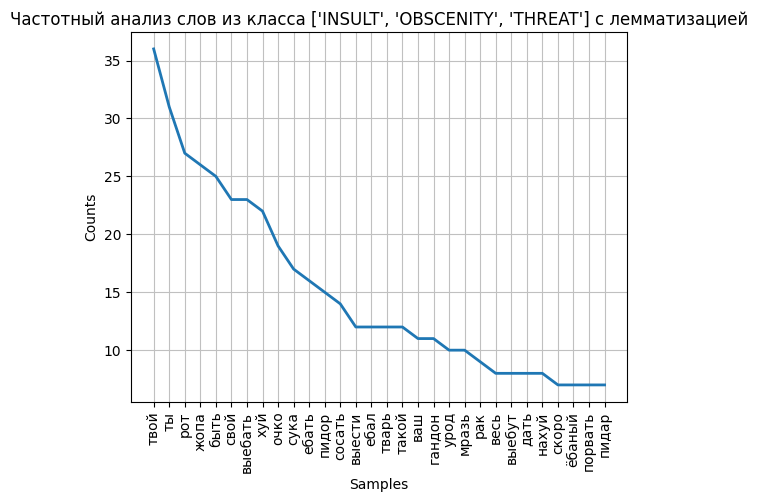

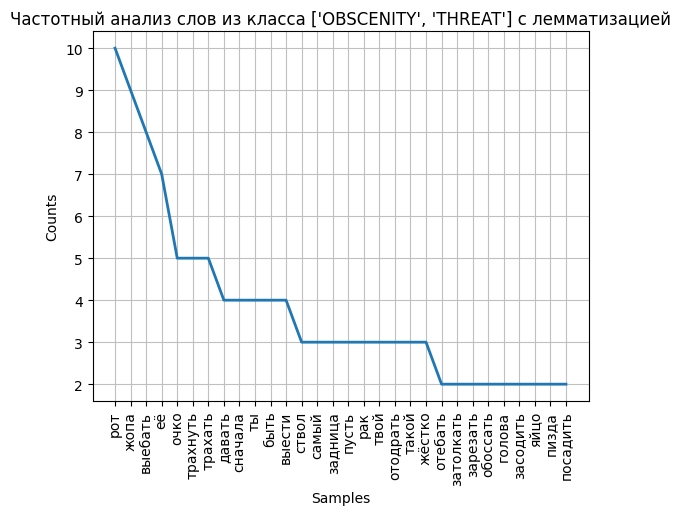

In [348]:
morph = pymorphy2.MorphAnalyzer()

for labels in labels_list:
    comments = " ".join(df[df['labels_str'] == '_'.join(labels)]['comment'].tolist())
    comments_tokens = word_tokenize(comments)
    text = nltk.Text(comments_tokens)
    text_lemmatized = map(lambda word: morph.parse(word)[0].normal_form, text)
    f_dist = FreqDist(text_lemmatized)
    f_dist.plot(30, cumulative=False, title=f'Частотный анализ слов из класса {labels} с лемматизацией')
    plt.show()


Впринципе то же самое что и показал Word Cloud

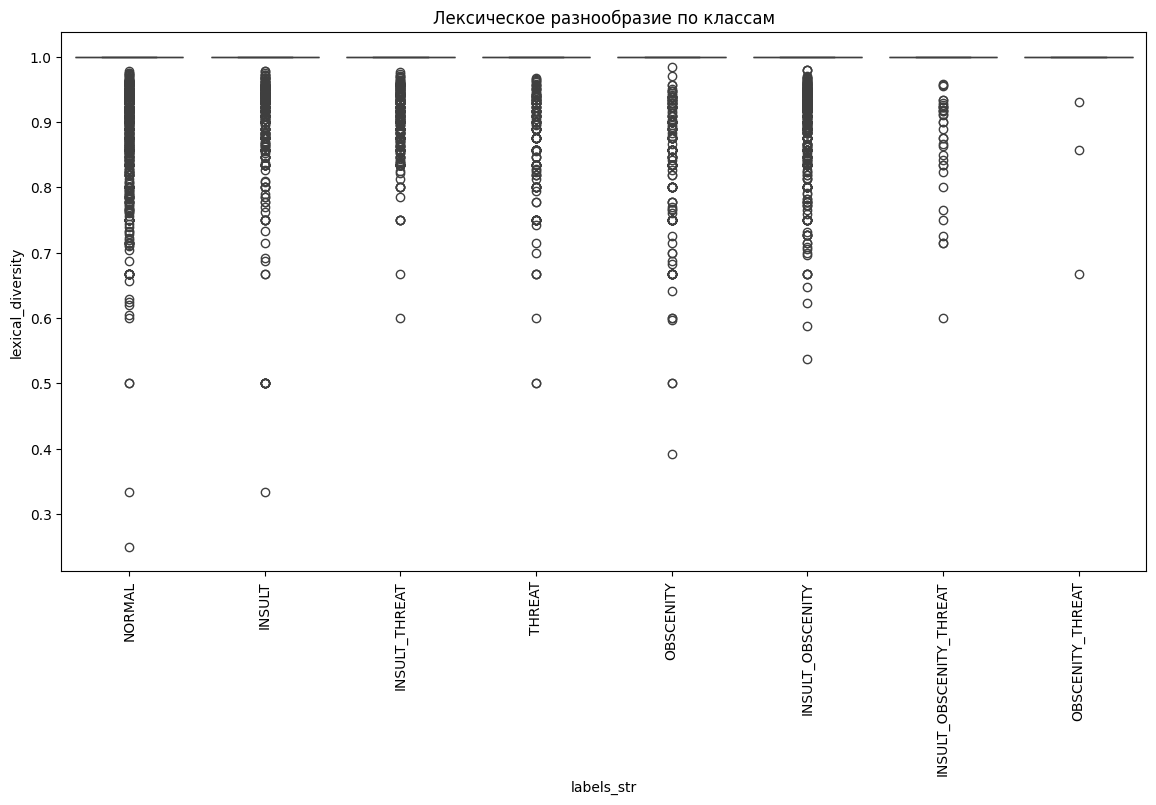

In [349]:
import seaborn as sns


df['lexical_diversity'] = df['comment_lemmatized'].apply(lambda x: (len(set(x)) / (len(x) if len(x) != 0 else 1)))


plt.figure(figsize=(14, 7))
sns.boxplot(df, x='labels_str', y='lexical_diversity')
plt.title('Лексическое разнообразие по классам')
plt.xticks(rotation=90)
plt.show()

Попробуем выделить один класс если их указано несколько и посмотреть на график снова

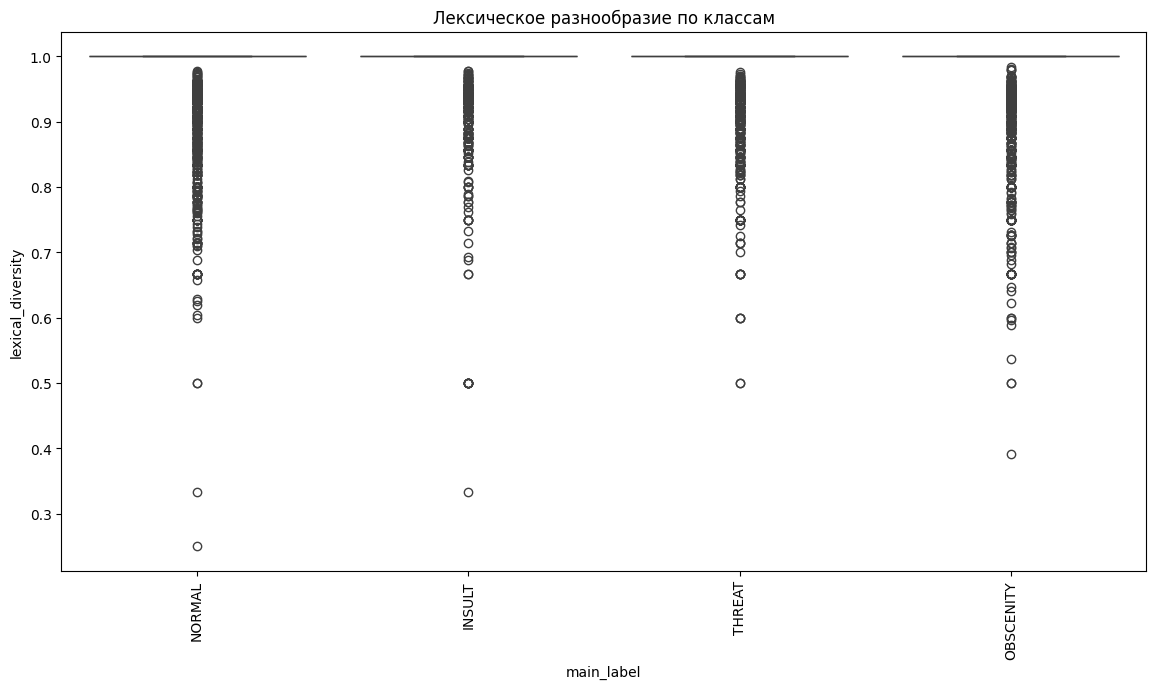

In [350]:
import seaborn as sns


def get_main_label(x):
    order = ['NORMAL', 'THREAT', 'OBSCENITY', 'INSULT']
    for label in order:
        if label in x:
            return label
    return 'NORMAL'


df['lexical_diversity'] = df['comment_lemmatized'].apply(lambda x: (len(set(x)) / (len(x) if len(x) != 0 else 1)))
df['main_label'] = df['labels'].map(get_main_label)

plt.figure(figsize=(14, 7))
sns.boxplot(df, x='main_label', y='lexical_diversity')
plt.title('Лексическое разнообразие по классам')
plt.xticks(rotation=90)
plt.show()

In [351]:
df[df['lexical_diversity'] <= 0.5]['comment'].tolist()

['нужна помощь поддержка дружеская хватает хозяйстве вещи малой дела важного нужно масло подсолн нужна помощь поддержка дружеская хватает хозяйстве вещи малой дела важного нужно масло подсолн нужна помощь поддержка дружеская хватает хозяйстве вещи малой дела важного нужно масло подсолн нужна помощь поддержка дружеская хватает хозяйстве вещи малой дела важного нужно масло подсолн',
 'здоровья здоровья здоровья',
 'актёров дети актёры врачей дети врачи',
 'турки турки',
 'пидор пидор',
 'пидор пидор',
 'идиоты знаем идиотыи знают знаем идиоты',
 'гнида гнида',
 'пидор пидор',
 'дебил дебиле дебилом погоняют',
 'жопа плечах плечи жопе',
 'блядь бляди блядью погоняет',
 'тварь тварь тварь',
 'смерть смерть',
 'вешать вешать',
 'ебать ебать',
 'ебать ебать',
 'хочу ванессу хочу поиметь ванессу хочу выебать ванессу хочу трахнуть ванессу хочу вдуть ванессе хочу заполнить ванессу хочу нагнуть ванессу хочу взять ванессу']

В целом очень похоже на выбросы, можем удалить их и посмотреть снова

In [352]:
df = df[df['lexical_diversity'] > 0.5]

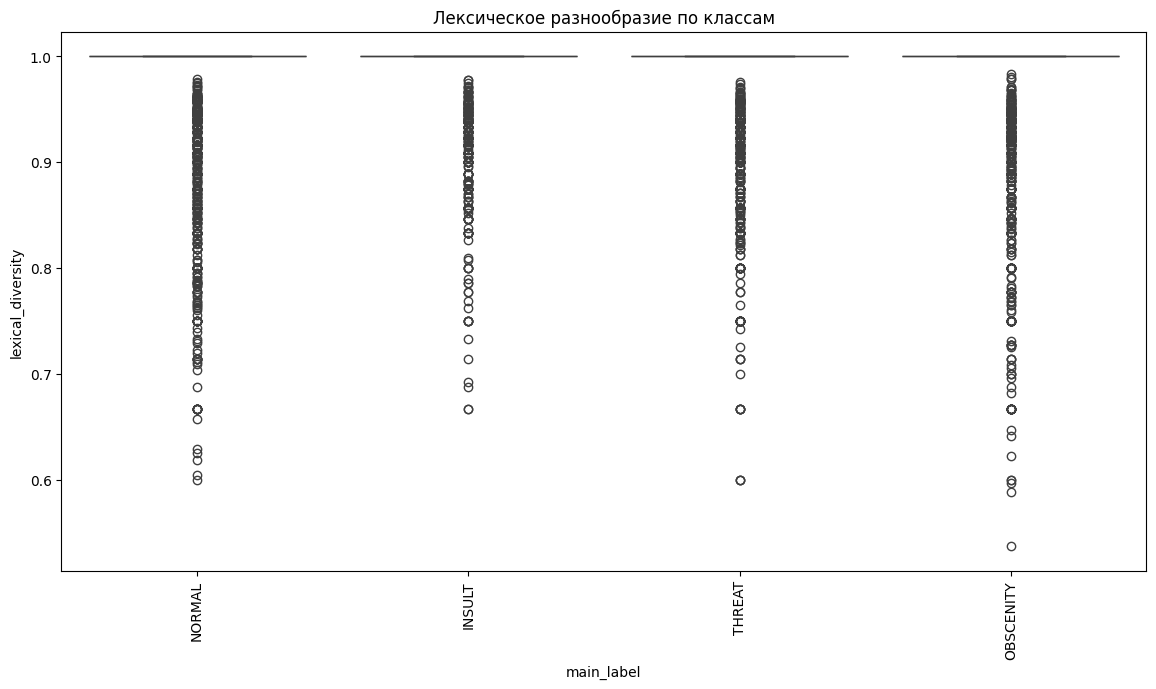

In [353]:
plt.figure(figsize=(14, 7))
sns.boxplot(df, x='main_label', y='lexical_diversity')
plt.title('Лексическое разнообразие по классам')
plt.xticks(rotation=90)
plt.show()

Надо подумать, можем ли мы что то извлечь полезное из этого графика, пока что кажется, что в целом классы очень похожи по лексикографическому разнообразию.

Посмотрим на кластеры при снижении размерности

In [354]:
# векторизация
from sklearn.feature_extraction.text import TfidfVectorizer


tf_idf_vectorizer = TfidfVectorizer()
df_vec = tf_idf_vectorizer.fit_transform(df['comment_lemmatized'].apply(lambda x: ' '.join(x))).toarray()
df_vec = pd.DataFrame(df_vec, index=df.index, columns=tf_idf_vectorizer.get_feature_names_out())
df_vec.head()

,аа,ааа,ааааау,аааотвечать,ааат,аагепагал,аан,аанальный,ааптиа,аасраф,...,ёж,ёжик,ёй,ёлка,ёлыпалый,ёнок,ёпнулосолбдать,ёпрограммукто,ёпт,ёрш
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [355]:
RANDOM_STATE = 52

In [356]:
from sklearn.manifold import TSNE


tsne = TSNE(n_components=2, random_state=RANDOM_STATE, perplexity=3, max_iter=500)
tsne_results = tsne.fit_transform(df_vec)

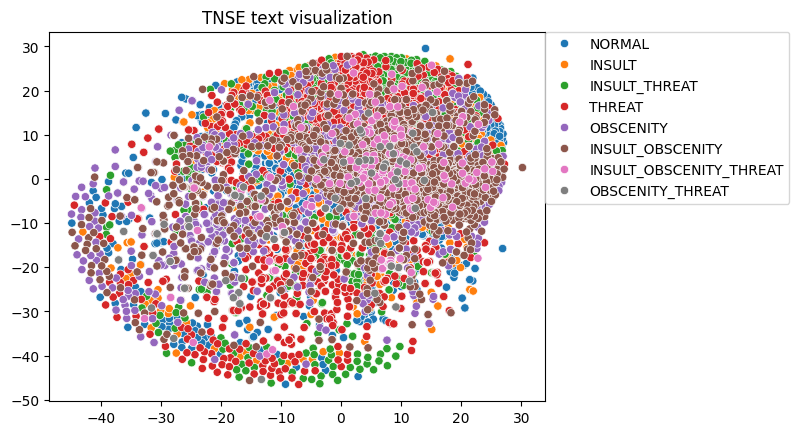

In [357]:
sns.scatterplot(x=tsne_results[:, 1], y=tsne_results[:, 0], hue=df['labels_str']);
plt.legend(bbox_to_anchor=(1, 1), loc=2, borderaxespad=0.);
plt.title('TNSE text visualization');

In [358]:
from sklearn.decomposition import PCA


pca = PCA(n_components=2)
pca_results = pca.fit_transform(df_vec)

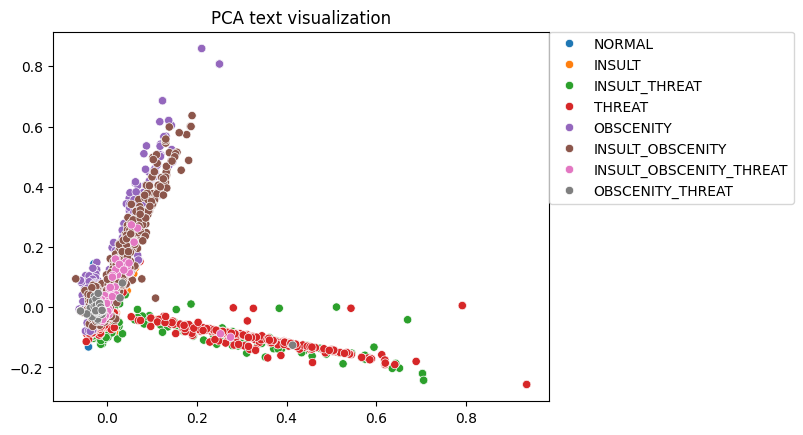

In [359]:
sns.scatterplot(x=pca_results[:, 1], y=pca_results[:, 0], hue=df['labels_str']);
plt.legend(bbox_to_anchor=(1, 1), loc=2, borderaxespad=0.);
plt.title('PCA text visualization');

In [360]:
from sklearn.decomposition import TruncatedSVD


svd = TruncatedSVD(n_components=2)
svd_results = svd.fit_transform(df_vec)

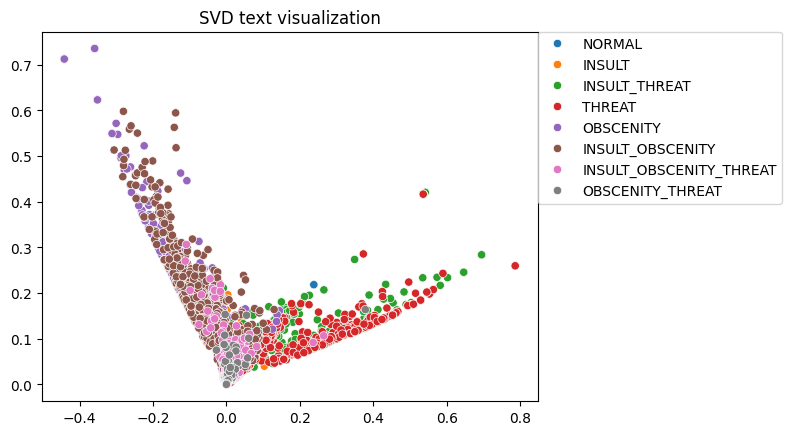

In [361]:
sns.scatterplot(x=svd_results[:, 1], y=svd_results[:, 0], hue=df['labels_str']);
plt.legend(bbox_to_anchor=(1, 1), loc=2, borderaxespad=0.);
plt.title('SVD text visualization');

Очень интересный первый график, на нем пока не особо заметно разделение на классы, несмотря на то что выбросы мы почистили. Я думаю можно поподбирать параметр perplexity и посмотрееть на визуализацию.

На втором и третьем графике явно видно разделение на кластеры классов THREAT и INSULT_THREAT